# 02｜傳統機器學習：2×2 基準矩陣
| Run | Representation | Classifier |
|---|---|---|
| ML-01 | BoW | KNN（cosine brute） |
| ML-02 | BoW | SVC（linear kernel） |
| ML-03 | TF-IDF | KNN（cosine brute） |
| ML-04 | TF-IDF | SVC（linear kernel） |

本 Notebook 只使用 v1.1 Train 19,823、Validation 4,956。Validation F1 用來選 k / C，官方 Test 保留到 Gate E。


In [1]:
from pathlib import Path
import json,sys
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
assert ROOT.is_dir()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display,Image
from src.evaluation import phase1_settings
settings,phase1_hash,manifest=phase1_settings()
print('Variant:',manifest['version'])
print('Split SHA256:',manifest['split_assignments_sha256'])
print('Phase1 SHA256:',phase1_hash)
assert settings['test_policy']=='do_not_evaluate_in_phase1'
from src.evaluation import subset_data
train,val=subset_data()
assert len(train)==19823 and len(val)==4956
print('Train',len(train),'Validation',len(val))
print('KNN candidates:',settings['ml']['knn']['k_candidates'])
print('SVC candidates:',settings['ml']['svc']['C_candidates'])


Variant: dedup_v1.1
Split SHA256: 9e25b0d714d1fb555c8c8a58fa6858c392ec60ecfba554b923553626154174e9
Phase1 SHA256: 5b3e976e16d73ab101abd41f9d022a13d319d221760625f3c6586d1db8d64d29
Train 19823 Validation 4956
KNN candidates: [3, 5]
SVC candidates: [0.1, 1.0]


## 1. 共用特徵矩陣
向量器於 Phase 0 v1.1 僅 fit Train。KNN / SVC 使用相同 sparse matrix。

In [2]:
from scipy.sparse import load_npz
art=ROOT/'artifacts/vectorizers'
for name in ('bow','tfidf'):
    X=load_npz(art/(name+'_train.npz'))
    V=load_npz(art/(name+'_validation.npz'))
    assert X.shape==(19823,12000) and V.shape==(4956,12000)
    print(name,'train',X.shape,'validation',V.shape,
          'train sparsity:',round(1-X.nnz/(X.shape[0]*X.shape[1]),4))


bow train (19823, 12000) validation (4956, 12000) train sparsity: 0.989
tfidf train (19823, 12000) validation (4956, 12000) train sparsity: 0.989


## 2. 正式訓練四個基準條件
原生 sklearn KNeighborsClassifier：metric=cosine、algorithm=brute、k ∈ {3,5}。
原生 sklearn.svm.SVC：kernel=linear、C ∈ {0.1,1.0}。相同候選範圍，各組只用 Validation F1 定案。

已存在完整 Run 的模型與預測不重訓；僅補做缺漏組別。
每組完整訓練、候選指標、預測耗時及選擇理由皆保留。


In [3]:
import subprocess
wanted=['ML-01-s42','ML-02-s42','ML-03-s42','ML-04-s42']
registry=ROOT/'results/runs.csv'
existing=set(pd.read_csv(registry).run_id) if registry.exists() else set()
missing=[name[:-4] for name in wanted if name not in existing]
print('Missing full-data models:',missing)
if missing:
    subprocess.run([sys.executable,'-B','-m','src.phase1_ml','--runs',*missing],cwd=ROOT,check=True)
print('Four baseline conditions completed.')


Missing full-data models: []
Four baseline conditions completed.


## 3. Validation 指標與超參數紀錄
各模型同時計算 Accuracy、Precision、Recall、F1、Confusion Matrix；測試集尚未參與。

In [4]:
rows=pd.read_csv(ROOT/'results/runs.csv')
selected=rows[rows.run_id.isin(wanted)].sort_values('run_id')
assert len(selected)==4 and selected.run_id.is_unique
display(selected[['run_id','representation','model_name','val_accuracy','val_precision',
                  'val_recall','val_f1','train_time_sec','inference_time_sec']].round(4))
for rid in selected.run_id:
    diag=json.loads((ROOT/('results/'+rid+'_candidate_selection.json')).read_text())
    print(rid,'selected:',diag['chosen_parameter'],
          'validation candidates:',[(x['value'],round(x['val_f1'],4)) for x in diag['candidates']])


,run_id,representation,model_name,val_accuracy,val_precision,val_recall,val_f1,train_time_sec,inference_time_sec
0,ML-01-s42,bow,KNeighborsClassifier,0.6435,0.6368,0.6750,0.6554,0.0058,2.0819
4,ML-02-s42,bow,SVC,0.8767,0.8771,0.8775,0.8773,194.5276,34.2910
5,ML-03-s42,tfidf,KNeighborsClassifier,0.7686,0.7509,0.8067,0.7778,0.0030,1.8270
6,ML-04-s42,tfidf,SVC,0.8921,0.8874,0.8992,0.8932,274.2794,48.0708


ML-01-s42 selected: 5 validation candidates: [(3, 0.6437), (5, 0.6554)]
ML-02-s42 selected: 0.1 validation candidates: [(0.1, 0.8773), (1.0, 0.8554)]
ML-03-s42 selected: 5 validation candidates: [(3, 0.7649), (5, 0.7778)]
ML-04-s42 selected: 1.0 validation candidates: [(0.1, 0.8815), (1.0, 0.8932)]


## 4. 圖表：Validation F1 與混淆矩陣
所有圖表均來自 Validation，未使用 Test。

ML-01-s42


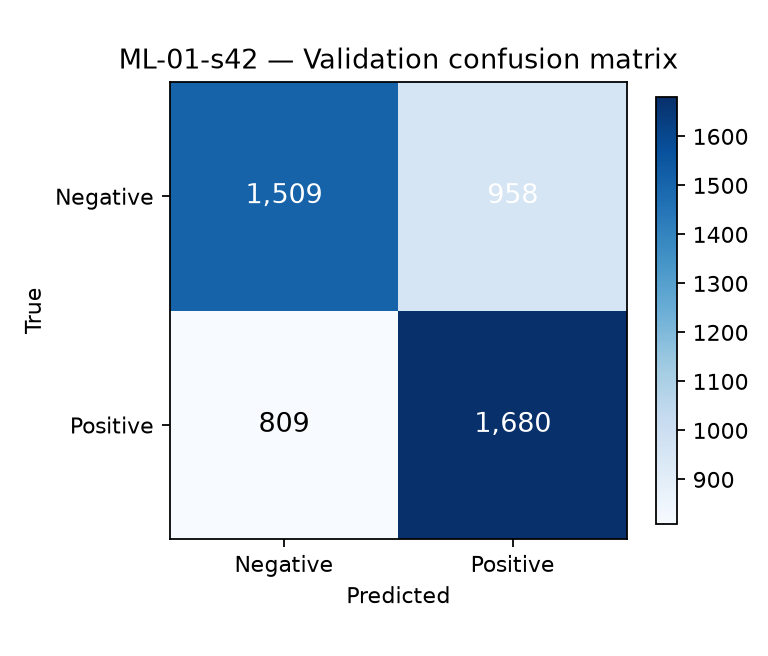

ML-02-s42


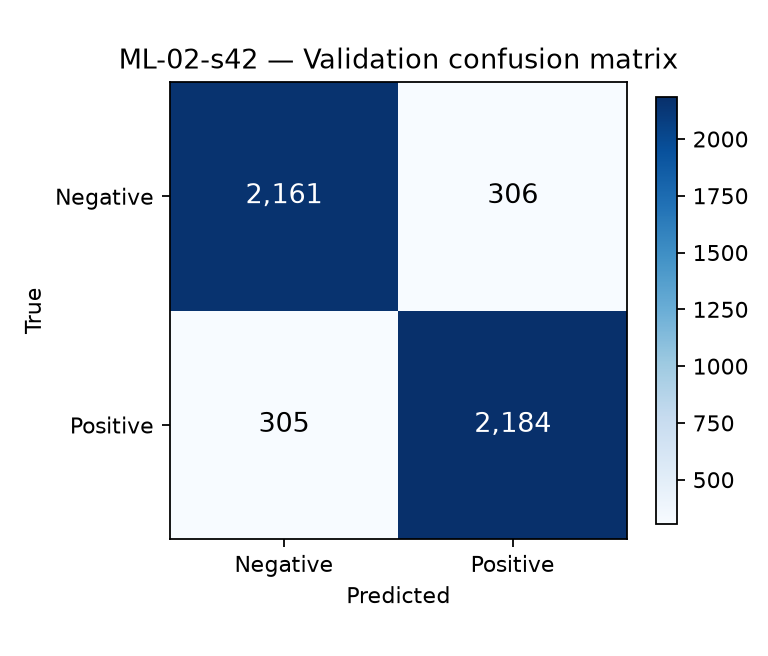

ML-03-s42


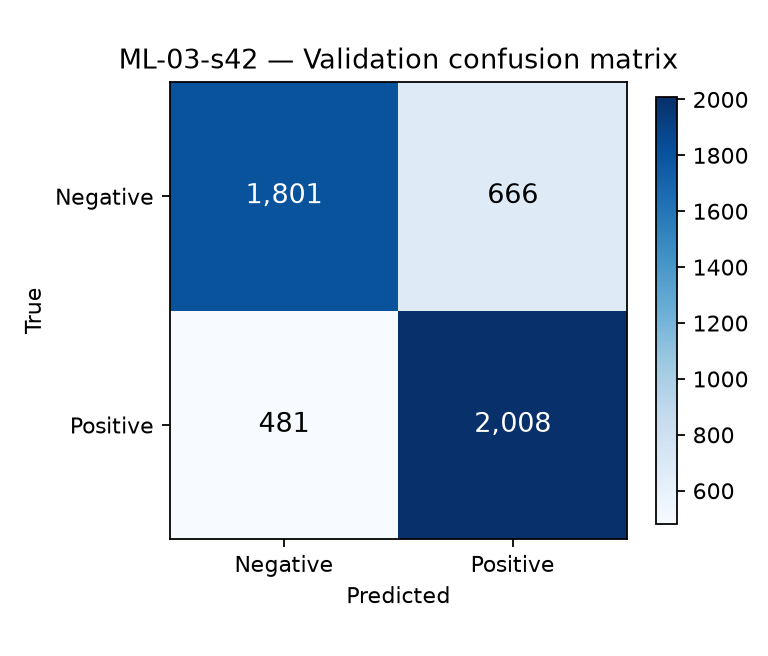

ML-04-s42


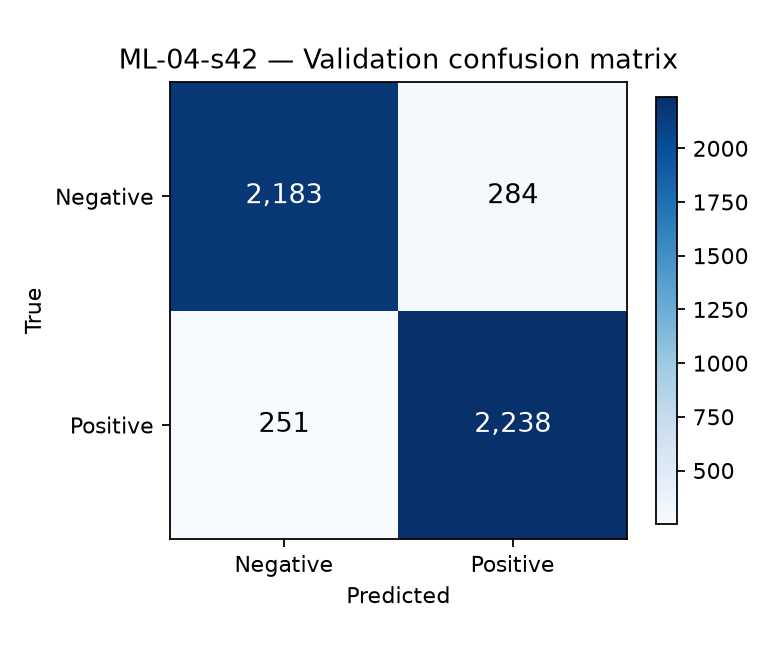

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,3.8))
ax.bar(selected.run_id,selected.val_f1)
ax.set(ylim=(0,1),ylabel='Validation F1',title='ML Baselines — dedup_v1.1')
ax.grid(axis='y',alpha=.2)
plt.show()
for rid in selected.run_id:
    print(rid)
    display(Image(filename=str(ROOT/('results/figures/'+rid+'_val_confusion_matrix.png')),width=360))


## Phase 1 ML 結果
正式模型保存於 artifacts/models，候選紀錄與 predictions 保存於 results。
KNN 的高維余弦暴力搜尋耗時需與 SVC 的訓練時間分開解釋。